In [1]:
from microtorch.model_maker import ModelMaker
from microtool.microtorch import MicrotorchTissueModel
from microtool.tissue_model import RelaxationTissueModel

microtorch_model = ModelMaker("Ball")
micro_ball_model = MicrotorchTissueModel(
    microtorch_model,
    parameters={"D": 2.0},
)

# micro_ball_model = RelaxationTissueModel(model=micro_ball_model, t2=0.1)



# micro_ball_model["T2"].optimize = False
# micro_ball_model["T2"].fit_flag = False
print(micro_ball_model)

No YAML configuration found for Ball model.
Falling back to parsing model name for compartments: ['Ball'].
Parameter ranges will be the default compartment values.
-----------
########### Making model:  Ball
########### Compartments: ['Ball']
########### Parameter names: [['D']]
########### Parameter ranges: [[[0.001, 3]]]
-----------
Tissue model with 2 scalar parameters:
Tissue-parameter      Value    Scale  Optimize    Fit    Fit Bounds
------------------  -------  -------  ----------  -----  ------------
D                         2        1  True        True   (0.001, 3.0)
S0                        1        1  False       False  (0.0, 2.0)


In [2]:
from microtool.misst import _get_matlab_engine, set_misst_path, convert_acquisition_scheme
from microtool.tissue_model import TissueParameter
from microtool.misst import MisstTissueModel

# 2. Setup MATLAB engine & MISST
set_misst_path('/home/jgroot34/MISST/MISST_v0.95/MISST')
engine = _get_matlab_engine()

ball_parameters = {
    "diff": TissueParameter(
        value=2.0e-9,
        scale=1e-9,
        optimize=True,
        fit_flag=True,
        fit_bounds=(0.1e-9, 3.5e-9),
    )
}
MISST_ball_model = MisstTissueModel(name="Ball", parameters=ball_parameters)

# MISST_ball_model = RelaxationTissueModel(model=Ball_MISST, t2=0.1)

# MISST_ball_model["T2"].optimize = False
# MISST_ball_model["T2"].fit_flag = False

print(MISST_ball_model)


Starting MATLAB engine...
MATLAB 2025b started.
Tissue model with 2 scalar parameters:
Tissue-parameter      Value    Scale  Optimize    Fit    Fit Bounds
------------------  -------  -------  ----------  -----  ----------------
diff                  2e-09    1e-09  True        True   (1e-10, 3.5e-09)
S0                    1        1      False       True   (0.0, inf)


In [3]:
import numpy as np
from microtool.acquisition_scheme import DiffusionAcquisitionScheme
from microtool.gradient_sampling import sample_uniform_half_sphere

n_directions = 6
n_shells = 2
block_size = n_directions + 1  # b0 + n_directions

shell_bvals = [1500, 2500]
shell_deltas = [0.0258, 0.0205]
shell_Deltas = [0.0434, 0.0331]
initial_te = 0.09

# Build the measurements in shell blocks: b0, then six directions.
b_vals_list = []
pulse_durations_list = []
pulse_intervals_list = []
echo_times_list = []

for i in range(n_shells):
    b_vals_list.append(0.0)
    b_vals_list.extend([shell_bvals[i]] * n_directions)

    pulse_durations_list.extend([shell_deltas[i]] * block_size)
    pulse_intervals_list.extend([shell_Deltas[i]] * block_size)
    echo_times_list.extend([initial_te] * block_size)

b_vals = np.array(b_vals_list)
pulse_durations = np.array(pulse_durations_list)
pulse_intervals = np.array(pulse_intervals_list)
echo_times = np.array(echo_times_list)
directions = sample_uniform_half_sphere(len(b_vals))

initial_scheme = DiffusionAcquisitionScheme.from_bvals(
    b_values=b_vals,
    b_vectors=directions,
    pulse_durations=pulse_durations,
    pulse_intervals=pulse_intervals,
    echo_times=echo_times,
)

# TE and timing: one free value for each 7-measurement shell block.
for name in (
    "EchoTime",
    "DiffusionPulseDuration",
    "DiffusionPulseInterval",
):
    initial_scheme[name].set_repetition_period(block_size)

# Gradient magnitude: fix b0, then share one value across each shell's six DW measurements.
b0_mask = b_vals == 0
magnitude = initial_scheme["DiffusionPulseMagnitude"]
magnitude.set_fixed_mask(b0_mask)
magnitude.set_repetition_period(n_directions)

print("TE free indices:",
      np.flatnonzero(initial_scheme["EchoTime"].optimize_mask))
print("Timing free indices:",
      np.flatnonzero(initial_scheme["DiffusionPulseDuration"].optimize_mask))
print("Gradient free indices:",
      np.flatnonzero(magnitude.optimize_mask))

print(initial_scheme)


TE free indices: [0 7]
Timing free indices: [0 7]
Gradient free indices: [1 8]
Acquisition scheme with 14 measurements and 6 scalar parameters. 
total number of optimized parameters is 8:
  DiffusionPulseMagnitude [mT/mm] in (0.0, 0.065)    DiffusionGradientAnglePhi [rad] (fixed)    DiffusionGradientAngleTheta [rad] (fixed)    DiffusionPulseDuration [s] in (0.001, 0.1)    DiffusionPulseInterval [s] in (0.001, 0.1)    EchoTime [s] in (0.001, 0.1)
-------------------------------------------------  -----------------------------------------  -------------------------------------------  --------------------------------------------  --------------------------------------------  ------------------------------
                                       -0                                          2.45176                                       1.5708                                          0.0258                                        0.0434                            0.09
                          

In [4]:
micro_signal = micro_ball_model(initial_scheme)
print(micro_signal)

misst_signal = MISST_ball_model(initial_scheme)
print(misst_signal)


[1.         0.04978707 0.04978707 0.04978707 0.04978707 0.04978707
 0.04978707 1.         0.00673795 0.00673795 0.00673795 0.00673795
 0.00673795 0.00673795]
[1.         0.05081051 0.05081051 0.05081051 0.05081051 0.05081051
 0.05081051 1.         0.00702939 0.00702939 0.00702939 0.00702939
 0.00702939 0.00702939]


In [5]:
micro_jacobian = micro_ball_model.scaled_jacobian(initial_scheme)
print(micro_jacobian)

MISST_jacobian = MISST_ball_model.scaled_jacobian(initial_scheme)
print(MISST_jacobian)

[[ 0.        ]
 [-0.0746806 ]
 [-0.0746806 ]
 [-0.0746806 ]
 [-0.0746806 ]
 [-0.0746806 ]
 [-0.0746806 ]
 [ 0.        ]
 [-0.01684487]
 [-0.01684487]
 [-0.01684487]
 [-0.01684487]
 [-0.01684487]
 [-0.01684487]]
[[-0.        ]
 [-0.07569882]
 [-0.07569882]
 [-0.07569882]
 [-0.07569882]
 [-0.07569882]
 [-0.07569882]
 [-0.        ]
 [-0.01742464]
 [-0.01742464]
 [-0.01742464]
 [-0.01742464]
 [-0.01742464]
 [-0.01742464]]


/nfs/rtfs03/storage/home/jgroot34/miniforge3/envs/MICROtool/lib/python3.11/site-packages/torch/autograd/graph.py:1113: UserWarning: CUDA initialization: The NVIDIA driver on your system is too old (found version 12020). Please update your GPU driver by downloading and installing a new version from the URL: http://www.nvidia.com/Download/index.aspx Alternatively, go to: https://pytorch.org to install a PyTorch version that has been compiled with your version of the CUDA driver. (Triggered internally at /__w/pytorch/pytorch/c10/cuda/CUDAFunctions.cpp:119.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


In [6]:
from microtool.optimize import optimize_scheme

micro_optimal_scheme, _ = optimize_scheme(initial_scheme, micro_ball_model, noise_variance=0.05, method="trust-constr", solver_options = {
    "verbose": 2,
    "maxiter": 150
})

MISST_optimal_scheme, _ = optimize_scheme(initial_scheme, MISST_ball_model, noise_variance=0.05, method="trust-constr", solver_options = {
    "verbose": 2,
    "maxiter": 150
})


| niter |f evals|CG iter|  obj func   |tr radius |   opt    |  c viol  |
|-------|-------|-------|-------------|----------|----------|----------|
|   1   |   9   |   0   | +9.0645e-01 | 1.00e+00 | 8.67e-01 | 0.00e+00 |
|   2   |  18   |   1   | +1.1005e-01 | 2.00e+00 | 4.28e-02 | 0.00e+00 |
|   3   |  27   |   8   | +1.1171e-01 | 9.05e+00 | 4.59e-02 | 0.00e+00 |
|   4   |  27   |   8   | +1.1171e-01 | 4.52e+01 | 4.40e-02 | 0.00e+00 |
|   5   |  36   |  15   | +1.0683e-01 | 4.52e+01 | 1.44e-02 | 0.00e+00 |
|   6   |  45   |  22   | +9.4446e-02 | 4.52e+01 | 3.02e-02 | 0.00e+00 |


/nfs/rtfs03/storage/home/jgroot34/miniforge3/envs/MICROtool/lib/python3.11/site-packages/scipy/optimize/_differentiable_functions.py:737: UserWarning: delta_grad == 0.0. Check if the approximated function is linear. If the function is linear better results can be obtained by defining the Hessian as zero instead of using quasi-Newton approximations.
  self.H.update(delta_x, delta_g)


|   7   |  54   |  29   | +8.6189e-02 | 4.52e+01 | 2.82e-02 | 0.00e+00 |
|   8   |  63   |  36   | +7.7528e-02 | 4.52e+01 | 2.11e-02 | 0.00e+00 |
|   9   |  72   |  39   | +7.7449e-02 | 4.52e+01 | 1.55e-02 | 0.00e+00 |
|  10   |  72   |  39   | +7.7449e-02 | 2.26e+02 | 5.64e-03 | 0.00e+00 |
|  11   |  81   |  46   | +6.8050e-02 | 2.26e+02 | 1.09e-01 | 0.00e+00 |
|  12   |  90   |  48   | +6.7937e-02 | 2.26e+02 | 1.99e-02 | 0.00e+00 |
|  13   |  99   |  55   | +6.6492e-02 | 2.26e+02 | 1.93e-02 | 0.00e+00 |
|  14   |  108  |  62   | +6.2052e-02 | 2.26e+02 | 1.68e-02 | 0.00e+00 |
|  15   |  117  |  65   | +6.2018e-02 | 2.26e+02 | 1.56e-02 | 0.00e+00 |
|  16   |  126  |  72   | +6.1630e-02 | 2.26e+02 | 8.83e-02 | 0.00e+00 |
|  17   |  135  |  79   | +6.1216e-02 | 2.26e+02 | 1.51e-02 | 0.00e+00 |
|  18   |  144  |  86   | +5.8966e-02 | 2.26e+02 | 8.28e-02 | 0.00e+00 |
|  19   |  153  |  93   | +5.6855e-02 | 2.26e+02 | 3.14e-03 | 0.00e+00 |
|  20   |  162  |  100  | +5.4258e-02 | 2.26e+02 | 

/nfs/rtfs03/storage/home/jgroot34/miniforge3/envs/MICROtool/lib/python3.11/site-packages/scipy/optimize/_differentiable_functions.py:385: UserWarning: delta_grad == 0.0. Check if the approximated function is linear. If the function is linear better results can be obtained by defining the Hessian as zero instead of using quasi-Newton approximations.
  self.H.update(self.x - self.x_prev, self.g - self.g_prev)


|  73   |  648  |  373  | +3.9182e-02 | 1.13e+01 | 3.78e-02 | 0.00e+00 |
|  74   |  666  |  375  | +3.9182e-02 | 1.13e+00 | 3.78e-02 | 0.00e+00 |
|  75   |  684  |  378  | +3.9182e-02 | 1.13e-01 | 3.78e-02 | 0.00e+00 |
|  76   |  702  |  383  | +3.9182e-02 | 1.13e-02 | 3.78e-02 | 0.00e+00 |
|  77   |  720  |  389  | +3.9182e-02 | 5.66e-03 | 3.78e-02 | 0.00e+00 |
|  78   |  738  |  393  | +3.9182e-02 | 2.83e-03 | 3.78e-02 | 0.00e+00 |
|  79   |  756  |  397  | +3.9182e-02 | 1.41e-03 | 3.78e-02 | 0.00e+00 |
|  80   |  774  |  401  | +3.9182e-02 | 7.07e-04 | 3.78e-02 | 0.00e+00 |
|  81   |  792  |  405  | +3.9182e-02 | 3.53e-04 | 3.78e-02 | 0.00e+00 |
|  82   |  810  |  409  | +3.9182e-02 | 1.77e-04 | 3.78e-02 | 0.00e+00 |
|  83   |  828  |  412  | +3.9182e-02 | 8.84e-05 | 3.78e-02 | 0.00e+00 |
|  84   |  846  |  415  | +3.9182e-02 | 4.42e-05 | 3.78e-02 | 0.00e+00 |
|  85   |  864  |  418  | +3.9182e-02 | 2.21e-05 | 3.78e-02 | 0.00e+00 |
|  86   |  882  |  420  | +3.9182e-02 | 1.10e-05 | 

/smb/user/jgroot34/DS-Data/Radiotherapie/Research/User/jgroot34/D_Projects/MICROtool/MICROtool_Github/microtool/microtool/optimize/optimize.py:246: UserWarning: Optimization procedure was unsuccessful. Possible solutions include but are not limited to: Changing the optimizer settings, changing the optimization method or changing the initial scheme to a more suitable one. If you are using a scipy optimizer its settings can be changed by passing options to this function. If you are using a MICROtool optimization method please consult the optimization_methods module for more details.
  warnings.warn(


| niter |f evals|CG iter|  obj func   |tr radius |   opt    |  c viol  |
|-------|-------|-------|-------------|----------|----------|----------|
|   1   |   9   |   0   | +8.6683e-01 | 1.00e+00 | 3.05e+05 | 0.00e+00 |
|   2   |  18   |   1   | +3.5404e-01 | 1.00e+00 | 3.29e-01 | 0.00e+00 |
|   3   |  27   |   9   | +3.5404e-01 | 6.95e+00 | 3.57e-01 | 0.00e+00 |
|   4   |  36   |  16   | +3.5449e-01 | 6.95e+00 | 3.62e-01 | 0.00e+00 |
|   5   |  45   |  22   | +3.5449e-01 | 6.95e+00 | 3.62e-01 | 0.00e+00 |
|   6   |  63   |  30   | +3.5449e-01 | 6.95e-01 | 3.62e-01 | 0.00e+00 |
|   7   |  81   |  38   | +3.5449e-01 | 1.38e-01 | 3.62e-01 | 0.00e+00 |
|   8   |  99   |  44   | +3.5449e-01 | 6.89e-02 | 3.62e-01 | 0.00e+00 |
|   9   |  117  |  50   | +3.5449e-01 | 3.45e-02 | 3.62e-01 | 0.00e+00 |
|  10   |  135  |  56   | +3.5449e-01 | 1.72e-02 | 3.62e-01 | 0.00e+00 |
|  11   |  153  |  62   | +3.5449e-01 | 8.62e-03 | 3.62e-01 | 0.00e+00 |
|  12   |  171  |  68   | +3.5449e-01 | 2.83e-03 | 

In [7]:
print(micro_optimal_scheme)
print(micro_optimal_scheme.b_values)

print(MISST_optimal_scheme)
print(MISST_optimal_scheme.b_values)

Acquisition scheme with 14 measurements and 6 scalar parameters. 
total number of optimized parameters is 8:
  DiffusionPulseMagnitude [mT/mm] in (0.0, 0.065)    DiffusionGradientAnglePhi [rad] (fixed)    DiffusionGradientAngleTheta [rad] (fixed)    DiffusionPulseDuration [s] in (0.001, 0.1)    DiffusionPulseInterval [s] in (0.001, 0.1)    EchoTime [s] in (0.001, 0.1)
-------------------------------------------------  -----------------------------------------  -------------------------------------------  --------------------------------------------  --------------------------------------------  ------------------------------
                                       -0                                          2.45176                                       1.5708                                       0.0275895                                     0.043996                        0.0914084
                                        0.0164921                                 -2.57288               

In [ ]:
import microtool.optimize.methods as methods
from microtool.optimize import optimize_scheme

import numpy as np
from microtool.optimize.loss_functions import compute_loss, gauss_loss


method = methods.SOMA()
micro_optimal_scheme, _ = optimize_scheme(
    initial_scheme, micro_ball_model, noise_variance=0.02, method=method
)

print("Second starting:")
MISST_optimal_scheme, _ = optimize_scheme(
    initial_scheme, MISST_ball_model, noise_variance=0.02, method=method
)   



Second starting:


In [ ]:
print(micro_optimal_scheme)
print(micro_optimal_scheme.b_values)

print(MISST_optimal_scheme)
print(MISST_optimal_scheme.b_values)

Acquisition scheme with 14 measurements and 6 scalar parameters. 
total number of optimized parameters is 8:
  DiffusionPulseMagnitude [mT/mm] in (0.0, 0.065)    DiffusionGradientAnglePhi [rad] (fixed)    DiffusionGradientAngleTheta [rad] (fixed)    DiffusionPulseDuration [s] in (0.001, 0.1)    DiffusionPulseInterval [s] in (0.001, 0.1)    EchoTime [s] in (0.001, 0.1)
-------------------------------------------------  -----------------------------------------  -------------------------------------------  --------------------------------------------  --------------------------------------------  ------------------------------
                                       -0                                          2.45176                                       1.5708                                      0.00882441                                     0.0236262                       0.0366698
                                        0.0568161                                 -2.57288               

In [ ]:
from microtool.monte_carlo.simulation import MonteCarloSimulation
from scipy import stats

# loc is mean and scale is standard deviation
noise_distribution = stats.norm(loc=0, scale=0.1)

# Perform a Monte Carlo simulation using the initial scheme.
simulation = MonteCarloSimulation(initial_scheme, ball_model, noise_distribution, n_sim=500)
simulation.run()
initial = simulation.result

# Repeat the simulation using the optimized scheme.
simulation.set_scheme(optimal_scheme)
simulation.run()
optimal = simulation.result

Starting Monte Carlo with 500 simulations:   0%|          | 0/500 [00:00<?, ?it/s]/nfs/rtfs03/storage/home/jgroot34/miniforge3/envs/MICROtool/lib/python3.11/site-packages/scipy/optimize/_differentiable_functions.py:385: UserWarning: delta_grad == 0.0. Check if the approximated function is linear. If the function is linear better results can be obtained by defining the Hessian as zero instead of using quasi-Newton approximations.
  self.H.update(self.x - self.x_prev, self.g - self.g_prev)
Starting Monte Carlo with 500 simulations: 100%|██████████| 500/500 [00:05<00:00, 84.17it/s]


Tissue model with 3 scalar parameters:
Tissue-parameter      Value    Scale  Optimize    Fit    Fit Bounds
------------------  -------  -------  ----------  -----  -------------
model_D                 2      1      True        True   (0.001, 3.0)
T2                      0.1    0.001  False       False  (0.0001, 0.1)
S0                      1      1      False       False  (0.0, 2.0)


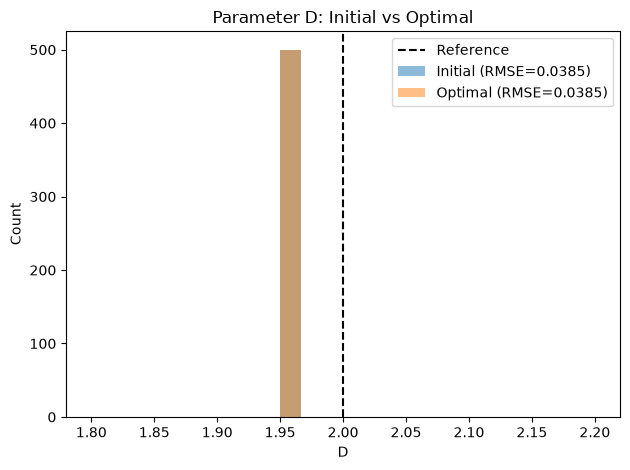

In [ ]:
from matplotlib import pyplot as plt
import numpy as np

initial_result = initial
optimal_result = optimal
print(ball_model)

# Reference value of D
reference = ball_model["model_D"].value

# Extract samples
initial_values = initial_result["D"]
optimal_values = optimal_result["D"]

# Calculate RMSE
initial_rmse = np.sqrt(np.mean((initial_values - reference) ** 2))
optimal_rmse = np.sqrt(np.mean((optimal_values - reference) ** 2))

# Histogram bins
bins = np.linspace(0.9 * reference, 1.1 * reference, 25)

plt.figure()

plt.axvline(
    reference,
    color="black",
    linestyle="--",
    label="Reference"
)

plt.hist(
    initial_values,
    bins=bins,
    alpha=0.5,
    label=f"Initial (RMSE={initial_rmse:.4f})"
)

plt.hist(
    optimal_values,
    bins=bins,
    alpha=0.5,
    label=f"Optimal (RMSE={optimal_rmse:.4f})"
)

plt.xlabel("D")
plt.ylabel("Count")
plt.title("Parameter D: Initial vs Optimal")
plt.legend()
plt.tight_layout()
plt.show()